In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


Load dataset

In [16]:
df = pd.read_csv("../data/sample_youtube_data.csv")

df.head()

,Channel,Month,Subscribers,Views,Likes
0,Tech World,Jan,100000,500000,25000
1,Tech World,Feb,115000,650000,32000
2,Tech World,Mar,128000,800000,40000
3,Tech World,Apr,145000,950000,47000
4,Tech World,May,170000,1200000,60000


Data inspection and exploratory data analysis

In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (15, 5)

Column Names:
['Channel', 'Month', 'Subscribers', 'Views', 'Likes']

Data Types:
Channel          str
Month            str
Subscribers    int64
Views          int64
Likes          int64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Channel      15 non-null     str  
 1   Month        15 non-null     str  
 2   Subscribers  15 non-null     int64
 3   Views        15 non-null     int64
 4   Likes        15 non-null     int64
dtypes: int64(3), str(2)
memory usage: 732.0 bytes

Statistical Summary:


,Subscribers,Views,Likes
count,15.000000,1.500000e+01,15.000000
mean,101600.000000,6.133333e+05,29600.000000
std,34706.524706,2.954093e+05,14029.560628
min,50000.000000,2.000000e+05,10000.000000
25%,76500.000000,4.000000e+05,19500.000000
50%,100000.000000,5.200000e+05,25000.000000
75%,124000.000000,8.250000e+05,39000.000000
max,170000.000000,1.200000e+06,60000.000000


Missing values

In [11]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Channel        0
Month          0
Subscribers    0
Views          0
Likes          0
dtype: int64


Duplicates

In [12]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


Data cleaning

In [17]:
clean_df = df.copy()

# Remove completely empty rows
clean_df = clean_df.dropna(how="all")

# Remove extra spaces from text columns
clean_df["Channel"] = clean_df["Channel"].astype("string").str.strip()
clean_df["Month"] = clean_df["Month"].astype("string").str.strip()

# Convert numerical columns to numeric format
numeric_columns = ["Subscribers", "Views", "Likes"]

for column in numeric_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column], errors="coerce"
    )

# Identify invalid numerical values
for column in numeric_columns:
    clean_df.loc[clean_df[column] < 0, column] = float("nan")

# Remove records without essential information
clean_df = clean_df.dropna(subset=["Channel", "Month"])

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Fill missing numerical values with zero for this demo
clean_df[numeric_columns] = clean_df[numeric_columns].fillna(0)

print("Original Rows:", len(df))
print("Cleaned Rows:", len(clean_df))

clean_df.head()

Original Rows: 15
Cleaned Rows: 15


,Channel,Month,Subscribers,Views,Likes
0,Tech World,Jan,100000.0,500000.0,25000.0
1,Tech World,Feb,115000.0,650000.0,32000.0
2,Tech World,Mar,128000.0,800000.0,40000.0
3,Tech World,Apr,145000.0,950000.0,47000.0
4,Tech World,May,170000.0,1200000.0,60000.0


Histogram

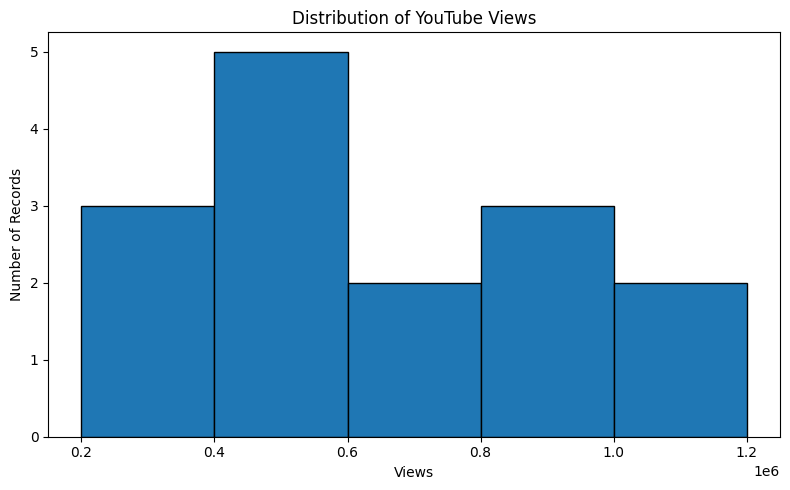

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(clean_df["Views"], bins=5, edgecolor="black")

plt.title("Distribution of YouTube Views")
plt.xlabel("Views")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

Scatter plot

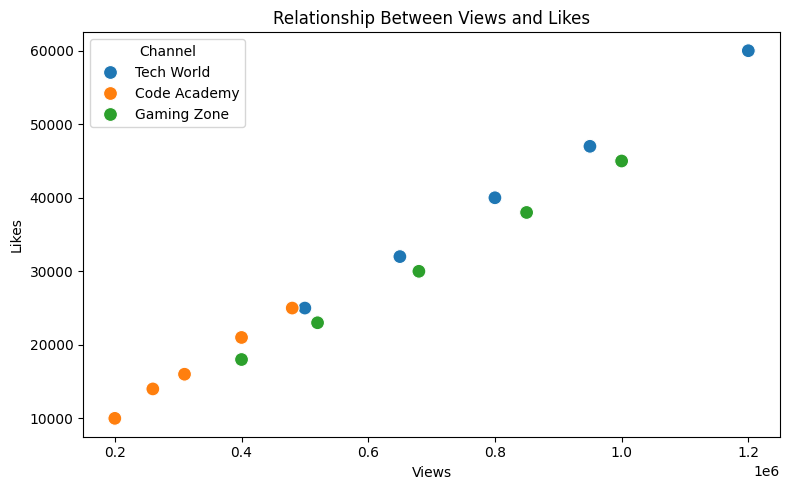

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x="Views",
    y="Likes",
    hue="Channel",
    s=100
)

plt.title("Relationship Between Views and Likes")
plt.xlabel("Views")
plt.ylabel("Likes")

plt.tight_layout()
plt.show()

Line plot

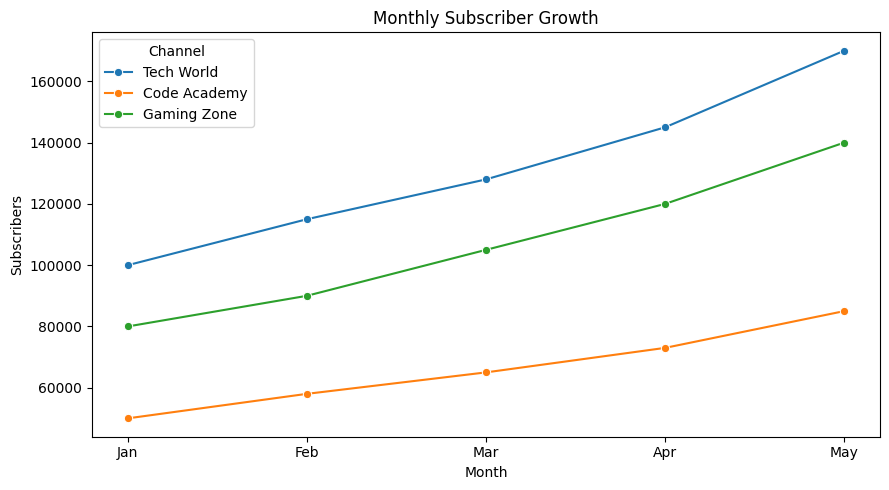

In [20]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=clean_df,
    x="Month",
    y="Subscribers",
    hue="Channel",
    marker="o"
)

plt.title("Monthly Subscriber Growth")
plt.xlabel("Month")
plt.ylabel("Subscribers")

plt.tight_layout()
plt.show()

Cleaned dataset

In [21]:
clean_df.to_csv(
    "../data/cleaned_youtube_data.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
